In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import MDAnalysis as mda
from MDAnalysis.analysis.align import alignto
from mg_sampling.density.align import standardize_names, reorder_residue_atoms, check_alignable, wrap_around_atomgroup, unwrap_sequential
from mg_sampling.density.grid import Grid
from mg_sampling.density.forward_density import atomgroup_to_map, voxels_around

from mg_sampling import PROJECT_DIR
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm

from tqdm import tqdm

In [8]:
# from MDAnalysis import AtomGroup
# from MDAnalysis.analysis.base import AnalysisBase, ResultsGroup

# from MDAnalysis import transformations

# class ForwardDensity(AnalysisBase):
#     @classmethod
#     def get_supported_backends(cls):
#         return ("serial", "multiprocessing", "dask")

#     _analysis_algorithm_is_parallelizable = True

#     def __init__(
#         self,
#         ag: AtomGroup,
#         shape: tuple[int],
#         delta: tuple[float],
#         origin: tuple[float] = (0, 0, 0),
#         vox_indices: list[int] | None = None,
#         device: str | None = None,
#         chunk_size: int | None = None,
#         **kwargs,
#     ):
#         super().__init__(ag.universe.trajectory, **kwargs)
#         self.ag = ag
#         self.shape = shape
#         self.delta = delta
#         self.origin = origin
#         self.vox_indices = vox_indices
#         self.device = device
#         self.chunk_size = chunk_size
    
#     def _prepare(self):
#         self.results.maps = []

#     def _single_frame(self):
#         map_ = atomgroup_to_map(
#             self.ag,
#             shape=self.shape,
#             delta=self.delta,
#             origin=self.origin,
#             vox_indices=self.vox_indices,
#             device=self.device,
#             chunk_size=self.chunk_size,
#         )
#         self.results.maps.append(map_)

#     def _get_aggregator(self):
#         return ResultsGroup(lookup={"maps": ResultsGroup.flatten_sequence})

# # class GlobalAlignTransform(TransformationBase):
# #     def __init__(self, mob_out, mob_align, ref_align):
# #         super().__init__()
# #         self.mob_out = mob_out
# #         self.mob_align = mob_align
# #         self.ref_align = ref_align

# #     def _transform(self, ts):
        
# #         ts = unwrap_sequential(ts, self.mob_align)
# #         #wrap_around_atomgroup(mob_out_not_align, mob_align_light)
# #         ts = wrap_around(ts, self.mob_out, self.mob_align.center_of_mass())
# #         mda.analysis.align.alignto(self.mob_align, self.ref_align, subselection=self.mob_out)
# #         return ts

# class unwrap_sequential(transformations.TransformationBase):
#     """
#     Unwrap sequentially atoms in `ag` using PLUMED "make whole" algorithm.
#     Each atom is placed at its closest image frow the previous one.
#     """
#     def __init__(self, ag):
#         super().__init__()
#         self.ag = ag

#     def _transform(self, ts):
#         pos = self.ag.positions
#         Δpos = np.diff(pos, axis=0, prepend=pos[[0]])
#         Δpos = mda.lib.distances.minimize_vectors(Δpos, ts.dimensions)
#         new_pos = pos[0] + np.cumsum(Δpos, axis=0)
#         self.ag.positions = new_pos
#         return ts

In [4]:
out_radius = 10
device = 'cuda'
chunk_size = 8192

top_file = PROJECT_DIR / 'plain_md/7ez0/mMg_tip3p/rep00/input.gro'
traj_files = [PROJECT_DIR / f'plain_md/7ez0/mMg_tip3p/rep{i:02d}/run.xtc'
              for i in range(8)]

ref = mda.Universe(PROJECT_DIR / 'density/9CBU.pdb')
refmap = Grid(PROJECT_DIR / 'density/emd_42499.map', file_format='mrc')

u = mda.Universe(
    top_file,
    *traj_files,
)

standardize_names(u)

mob_align = reorder_residue_atoms(u.select_atoms('not type H and nucleic'))
mob_align_light = mob_align.select_atoms('name P')[::5]  # For efficiency
ref_align = reorder_residue_atoms(ref.select_atoms('not type H and nucleic and not (resid 22 and name P OP1 OP2)'))

vox_indices = voxels_around(ref_align, radius=5, **refmap.grid_params)

check_alignable(mob_align, ref_align)

mob_out = u.select_atoms("not type H")
mob_out = mob_out.select_atoms(f"group mob_align or around {out_radius} group mob_align", mob_align=mob_align, updating=True)


tot_map = None
for ts in tqdm(u.trajectory):
    unwrap_sequential(mob_align)
    wrap_around_atomgroup(mob_out, mob_align_light)
    alignto(mob_align, ref_align, subselection=mob_out)
    map_ = atomgroup_to_map(
        mob_out,
        shape=refmap.shape,
        delta=refmap.delta,
        origin=refmap.origin,
        vox_indices=vox_indices,
        device=device,
        chunk_size=chunk_size,
    )
    tot_map = map_ if tot_map is None else tot_map + map_
    

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
  0%|          | 17/48008 [00:15<12:13:42,  1.09it/s]


KeyboardInterrupt: 

In [10]:
def plot_map_slice(grid: Grid, plane='xy', depth=0.5, depth_mode='fraction', norm=None, cmap='RdBu_r', ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    
    if norm is None:
        norm = CenteredNorm()

    x_axis, y_axis = ['xyz'.index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, - 1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == 'fraction':
        k = int(depth * len(midpoints))
    elif depth_mode == 'index':
        k = int(depth)
    elif depth_mode == 'coord':
        k = int(np.searchsorted(midpoints, depth, side="left"))
    
    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))
    im = ax.imshow(grid.grid[s].T, origin='lower', norm=norm, cmap=cmap, extent=extent, **kwargs)

    ax.set_xlabel('xyz'[x_axis])
    ax.set_ylabel('xyz'[y_axis])

    return ax

<Axes: xlabel='x', ylabel='y'>

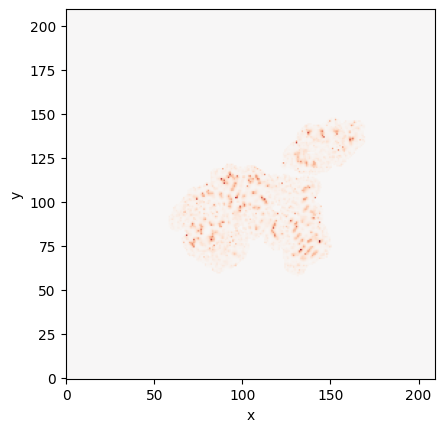

In [11]:
plot_map_slice(tot_map.to_dense())